In [1]:
# 01. Business Problem
USE_CASE = "Price Variance Detection"
EXCEPTION_VARIANCE_THRESHOLD = 0.20
CONTAMINATION_RATE = 0.05

print(f"Business Problem: {USE_CASE}")
print(f"Exception Threshold: {EXCEPTION_VARIANCE_THRESHOLD * 100:.0f}%")
print(f"Expected Anomaly Rate: {CONTAMINATION_RATE * 100:.0f}%")


Business Problem: Price Variance Detection
Exception Threshold: 20%
Expected Anomaly Rate: 5%


In [ ]:
# 02. Import Libraries
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import IsolationForest, RandomForestRegressor
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.svm import OneClassSVM
from sklearn.cluster import DBSCAN
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import (
    precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, confusion_matrix, roc_curve, precision_recall_curve
)

warnings.filterwarnings('ignore') 
%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 5)


In [3]:
# 03. Connect to Server
DB_HOST = "192.168.1.44"
DB_PORT = 5432
DB_NAME = "JKC_Input"
DB_SCHEMA = "HANA_P2"
DB_USER = "postgres"
DB_PASS = "postgres"

engine = create_engine(f"postgresql+psycopg2://{DB_USER}:{DB_PASS}@{DB_HOST}:{DB_PORT}/{DB_NAME}")

with engine.connect() as conn:
    print(f"Connected to PostgreSQL: {DB_HOST}:{DB_PORT}/{DB_NAME} (Schema: {DB_SCHEMA})")


Connected to PostgreSQL: 192.168.1.44:5432/JKC_Input (Schema: HANA_P2)


In [4]:
# 04. Extract Data
query = f"""
SELECT 
    p."EBELN" AS po_number,
    p."EBELP" AS po_item,
    p."MATNR" AS material_id,
    COALESCE(m."MAKTX", p."TXZ01") AS material_desc,
    ra."MTART" AS material_type,
    p."MATKL" AS material_group,
    p."WERKS" AS plant,
    w."NAME1" AS plant_name,
    k."LIFNR" AS vendor_id,
    v."NAME1" AS vendor_name,
    v."LAND1" AS vendor_country,
    k."BSART" AS doc_type,
    k."WAERS" AS currency,
    k."AEDAT" AS po_date,
    p."MENGE" AS order_quantity,
    p."MEINS" AS unit_of_measure,
    p."NETPR" AS po_unit_price,
    p."PEINH" AS po_price_unit,
    p."NETWR" AS po_net_value,
    e."NETPR" AS info_rec_price,
    e."PEINH" AS info_rec_price_unit
FROM "{DB_SCHEMA}"."EKPO" p
JOIN "{DB_SCHEMA}"."EKKO" k ON p."EBELN" = k."EBELN"
LEFT JOIN "{DB_SCHEMA}"."MAKT" m ON p."MATNR" = m."MATNR" AND m."SPRAS" = 'EN'
LEFT JOIN "{DB_SCHEMA}"."MARA" ra ON p."MATNR" = ra."MATNR"
JOIN "{DB_SCHEMA}"."LFA1" v ON k."LIFNR" = v."LIFNR"
JOIN "{DB_SCHEMA}"."T001W" w ON p."WERKS" = w."WERKS"
LEFT JOIN "{DB_SCHEMA}"."EINA" a ON p."MATNR" = a."MATNR" AND k."LIFNR" = a."LIFNR"
LEFT JOIN "{DB_SCHEMA}"."EINE" e ON a."INFNR" = e."INFNR"
WHERE p."MATNR" IS NOT NULL AND p."MATNR" != ''
  AND k."LIFNR" IS NOT NULL AND k."LIFNR" != ''
  AND p."NETPR" IS NOT NULL AND p."NETPR" > 0
ORDER BY k."AEDAT" DESC NULLS LAST
LIMIT 20000;
"""

df_raw = pd.read_sql(query, engine)
print(f"Extracted records: {len(df_raw):,} rows, {df_raw.shape[1]} columns")


Extracted records: 20,000 rows, 21 columns


In [5]:
# 05. Load Data
print(f"Dataset Shape: {df_raw.shape}")
df_raw[['po_number', 'material_id', 'material_desc', 'plant_name', 'vendor_name', 'po_unit_price']].head()


Dataset Shape: (20000, 21)


In [6]:
# 06. Data Understanding / EDA
df_raw[['order_quantity', 'po_unit_price', 'po_price_unit', 'po_net_value', 'info_rec_price']].describe().T


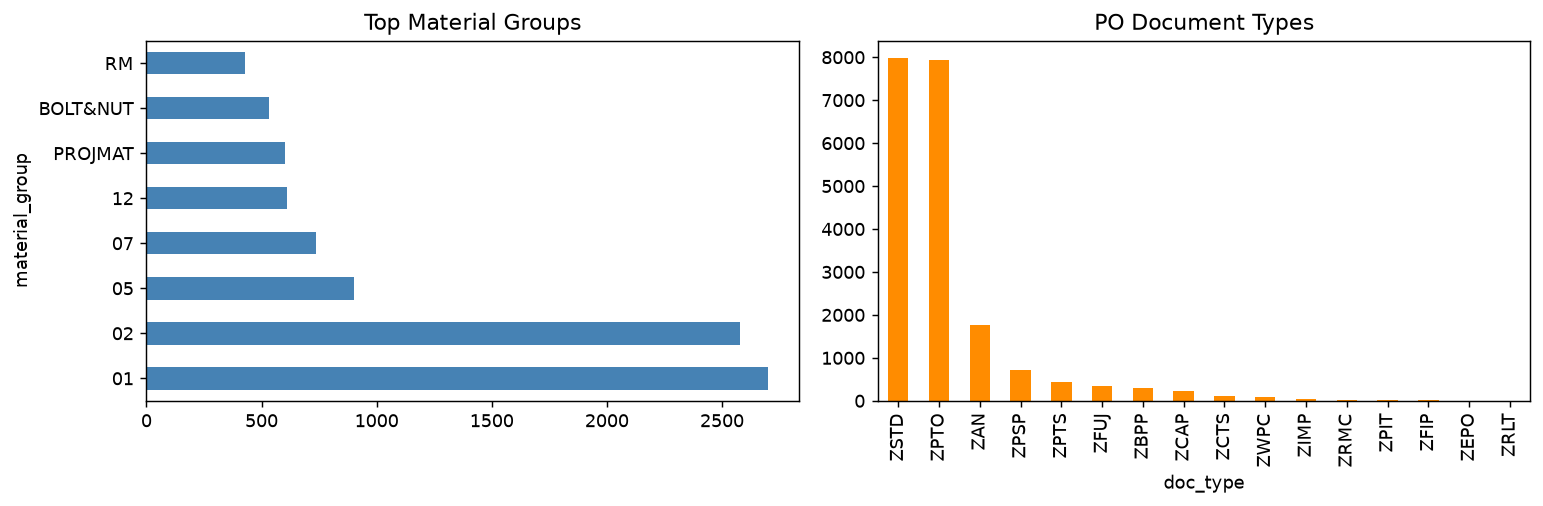

In [7]:
# 06. Data Understanding / EDA (Visualizations)
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
df_raw['material_group'].value_counts().head(8).plot(kind='barh', color='steelblue')
plt.title('Top Material Groups')

plt.subplot(1, 2, 2)
df_raw['doc_type'].value_counts().plot(kind='bar', color='darkorange')
plt.title('PO Document Types')
plt.tight_layout()
plt.show()


In [8]:
# 07. Data Cleaning
df = df_raw.copy()

df['po_price_unit'] = df['po_price_unit'].fillna(1).replace(0, 1)
df['info_rec_price_unit'] = df['info_rec_price_unit'].fillna(1).replace(0, 1)
df['order_quantity'] = df['order_quantity'].fillna(0)
df['po_net_value'] = df['po_net_value'].fillna(0)

print(f"Cleaned dataset: {len(df):,} records")


Cleaned dataset: 20,000 records


In [9]:
# 08. Feature Engineering
# 1. Effective Prices Normalized by Price Unit
df['effective_po_price'] = df['po_unit_price'] / df['po_price_unit']
df['effective_info_price'] = df['info_rec_price'] / df['info_rec_price_unit']
df['has_info_contract'] = (~df['effective_info_price'].isna() & (df['effective_info_price'] > 0)).astype(int)

# 2. Reference Benchmark Price (Contract Price -> Material Median -> Group Median)
mat_medians = df.groupby('material_id')['effective_po_price'].transform('median')
grp_medians = df.groupby('material_group')['effective_po_price'].transform('median')
grp_means = df.groupby('material_group')['effective_po_price'].transform('mean')
grp_stds = df.groupby('material_group')['effective_po_price'].transform('std').fillna(1.0).replace(0, 1.0)

df['reference_price'] = np.where(
    df['has_info_contract'] == 1,
    df['effective_info_price'],
    np.where(~mat_medians.isna(), mat_medians, grp_medians)
)
df['reference_price'] = df['reference_price'].fillna(df['effective_po_price']).replace(0, 0.01)

# 3. Variance Features
df['price_variance_abs'] = df['effective_po_price'] - df['reference_price']
df['price_variance_pct'] = ((df['effective_po_price'] - df['reference_price']) / df['reference_price']) * 100.0
df['price_ratio'] = df['effective_po_price'] / df['reference_price']
df['log_price_ratio'] = np.log1p(np.maximum(0, df['price_ratio']))
df['group_price_zscore'] = ((df['effective_po_price'] - grp_means) / grp_stds).clip(-10, 10).fillna(0)
df['vendor_price_diff'] = df['effective_po_price'] - mat_medians.fillna(df['effective_po_price'])
df['log_order_qty'] = np.log1p(np.maximum(0, df['order_quantity']))
df['log_net_value'] = np.log1p(np.maximum(0, df['po_net_value']))

df[['po_number', 'material_id', 'material_desc', 'vendor_name', 'effective_po_price', 'reference_price', 'price_variance_pct']].head()


In [10]:
# 09. Data Preprocessing
FEATURE_COLS = [
    'effective_po_price',
    'reference_price',
    'price_variance_abs',
    'price_variance_pct',
    'price_ratio',
    'log_price_ratio',
    'group_price_zscore',
    'vendor_price_diff',
    'log_order_qty',
    'log_net_value',
    'has_info_contract'
]

X_raw = df[FEATURE_COLS].replace([np.inf, -np.inf], np.nan).fillna(0)
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X_raw)

print(f"Preprocessed Feature Matrix: {X_scaled.shape}")


Preprocessed Feature Matrix: (20000, 11)


In [11]:
# 10. Define X and Y
y = (
    ((df['has_info_contract'] == 1) & (df['price_variance_pct'] > 15.0)) |
    (df['price_variance_pct'] > 25.0) |
    (df['group_price_zscore'] > 3.0)
).astype(int).values

df['is_variance_exception'] = y
X = X_raw.copy()

print(f"Total Records:      {len(y):,}")
print(f"Normal (Y=0):       {(y == 0).sum():,} ({(y == 0).mean()*100:.2f}%)")
print(f"Exceptions (Y=1):   {(y == 1).sum():,} ({(y == 1).mean()*100:.2f}%)")


Total Records:      20,000
Normal (Y=0):       15,821 (79.11%)
Exceptions (Y=1):   4,179 (20.89%)


In [12]:
# 11. Train/Test Split
X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X, y, df.index, test_size=0.20, random_state=42, stratify=y
)

scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Train Set: {X_train_scaled.shape[0]:,} samples")
print(f"Test Set:  {X_test_scaled.shape[0]:,} samples")


Train Set: 16,000 samples
Test Set:  4,000 samples


In [13]:
# 12. Model 1: Isolation Forest
iso_forest = IsolationForest(
    n_estimators=150,
    contamination=0.05,
    random_state=42,
    n_jobs=-1
)
iso_forest.fit(X_train_scaled)

preds_if = (iso_forest.predict(X_test_scaled) == -1).astype(int)
scores_if = -iso_forest.decision_function(X_test_scaled)

print(f"Isolation Forest Flagged: {preds_if.sum():,} anomalies out of {len(preds_if):,} test records")


Isolation Forest Flagged: 182 anomalies out of 4,000 test records


In [14]:
# 13. Model 2: Local Outlier Factor (LOF)
lof = LocalOutlierFactor(
    n_neighbors=25,
    contamination=0.05,
    novelty=True,
    n_jobs=-1
)
lof.fit(X_train_scaled)

preds_lof = (lof.predict(X_test_scaled) == -1).astype(int)
scores_lof = -lof.decision_function(X_test_scaled)

print(f"LOF Flagged: {preds_lof.sum():,} anomalies out of {len(preds_lof):,} test records")


LOF Flagged: 218 anomalies out of 4,000 test records


In [ ]:
# 14. Model 3: One-Class SVM
oc_svm = OneClassSVM(
    kernel='rbf',
    gamma='scale',
    nu=0.05
)
oc_svm.fit(X_train_scaled)

preds_svm = (oc_svm.predict(X_test_scaled) == -1).astype(int)
scores_svm = -oc_svm.decision_function(X_test_scaled)

print(f"One-Class SVM Flagged: {preds_svm.sum():,} anomalies out of {len(preds_svm):,} test records")


One-Class SVM Flagged: 186 anomalies out of 4,000 test records


In [16]:
# 15. Model 4: DBSCAN
dbscan = DBSCAN(eps=1.8, min_samples=20, n_jobs=-1)
train_labels = dbscan.fit_predict(X_train_scaled)

core_samples = X_train_scaled[dbscan.core_sample_indices_] if len(dbscan.core_sample_indices_) > 0 else X_train_scaled
nn = NearestNeighbors(n_neighbors=20, n_jobs=-1).fit(core_samples)

distances, _ = nn.kneighbors(X_test_scaled)
scores_db = distances[:, -1]
preds_db = (scores_db > 1.8).astype(int)

print(f"DBSCAN Flagged: {preds_db.sum():,} anomalies out of {len(preds_db):,} test records")


DBSCAN Flagged: 947 anomalies out of 4,000 test records


In [17]:
# 16. Model 5: Autoencoder
autoencoder = MLPRegressor(
    hidden_layer_sizes=(32, 16, 8, 16, 32),
    activation='relu',
    solver='adam',
    batch_size=128,
    learning_rate_init=0.005,
    max_iter=150,
    early_stopping=True,
    random_state=42
)
autoencoder.fit(X_train_scaled, X_train_scaled)

recon_train = autoencoder.predict(X_train_scaled)
recon_test = autoencoder.predict(X_test_scaled)

train_errors = np.mean(np.square(X_train_scaled - recon_train), axis=1)
scores_ae = np.mean(np.square(X_test_scaled - recon_test), axis=1)

ae_thresh = np.percentile(train_errors, 95)
preds_ae = (scores_ae >= ae_thresh).astype(int)

print(f"Autoencoder Flagged: {preds_ae.sum():,} anomalies out of {len(preds_ae):,} test records")


Autoencoder Flagged: 190 anomalies out of 4,000 test records


In [18]:
# 17. Model Evaluation
models_dict = {
    'Isolation Forest': {'preds': preds_if, 'scores': scores_if},
    'Local Outlier Factor': {'preds': preds_lof, 'scores': scores_lof},
    'One-Class SVM': {'preds': preds_svm, 'scores': scores_svm},
    'DBSCAN': {'preds': preds_db, 'scores': scores_db},
    'Autoencoder': {'preds': preds_ae, 'scores': scores_ae}
}

metrics = []
for name, res in models_dict.items():
    p, s = res['preds'], res['scores']
    prec = precision_score(y_test, p, zero_division=0)
    rec = recall_score(y_test, p, zero_division=0)
    f1 = f1_score(y_test, p, zero_division=0)
    auc = roc_auc_score(y_test, s)
    pr_auc = average_precision_score(y_test, s)
    tn, fp, fn, tp = confusion_matrix(y_test, p).ravel()

    metrics.append({
        'Model': name,
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-Score': round(f1, 4),
        'ROC-AUC': round(auc, 4),
        'PR-AUC': round(pr_auc, 4),
        'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn
    })

eval_df = pd.DataFrame(metrics).sort_values(by='F1-Score', ascending=False).reset_index(drop=True)
eval_df


Selected Champion Model: DBSCAN


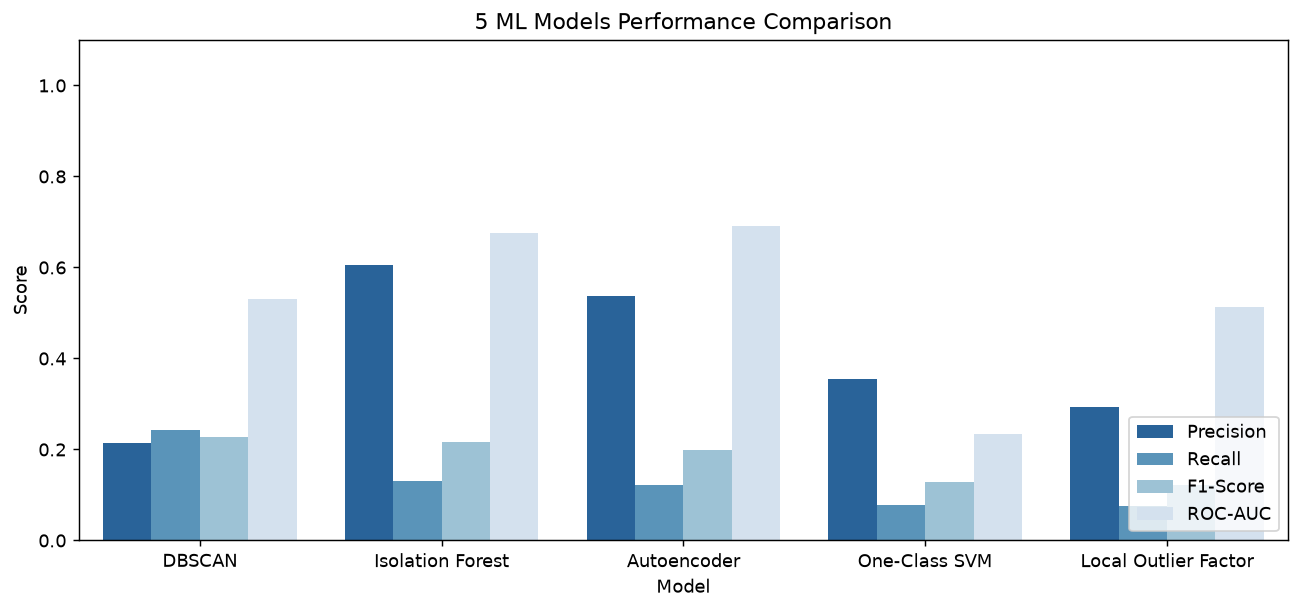

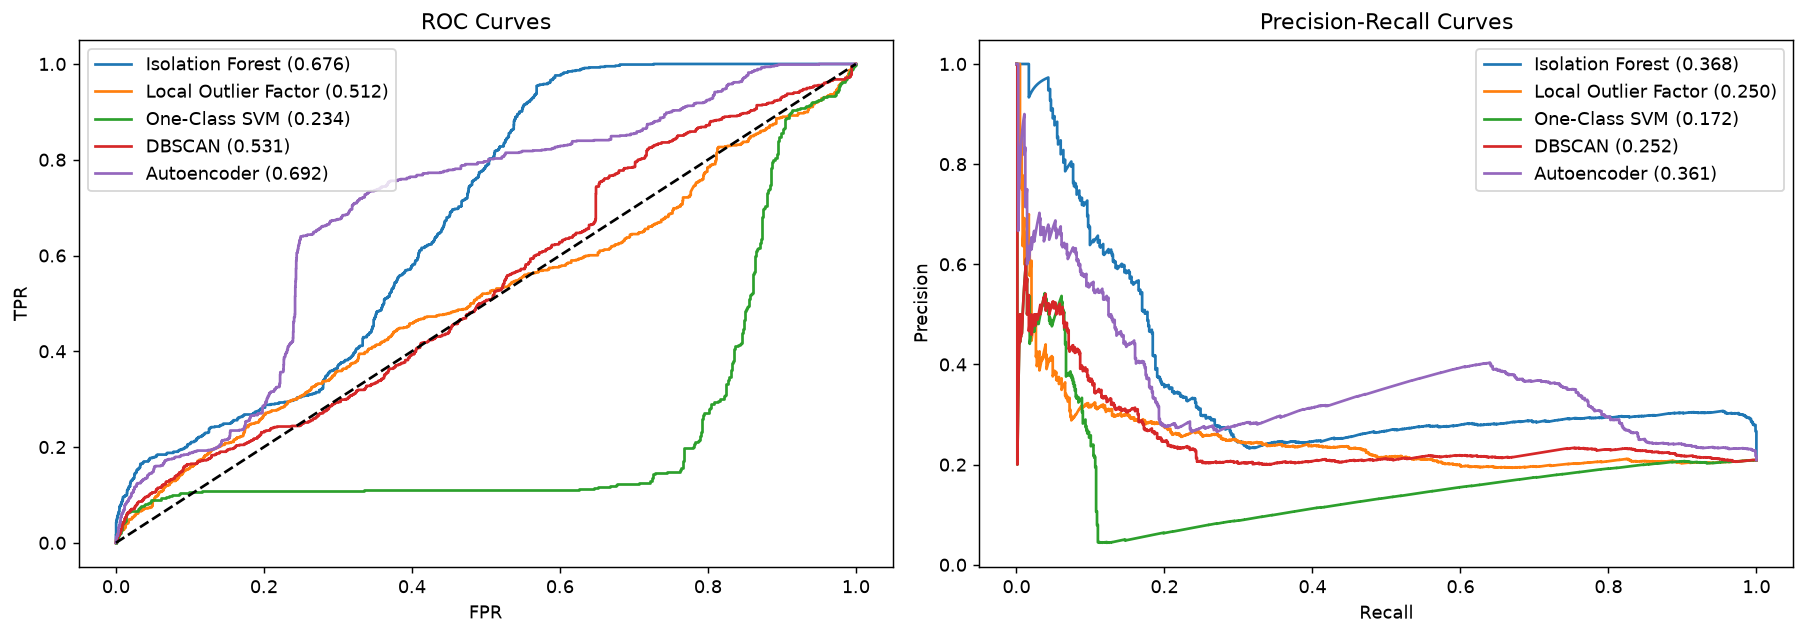

In [19]:
# 18. Model Comparison
plt.figure(figsize=(12, 5))
melted = pd.melt(eval_df, id_vars=['Model'], value_vars=['Precision', 'Recall', 'F1-Score', 'ROC-AUC'])
sns.barplot(data=melted, x='Model', y='value', hue='variable', palette='Blues_r')
plt.title('5 ML Models Performance Comparison')
plt.ylabel('Score')
plt.ylim(0, 1.1)
plt.legend(loc='lower right')
plt.show()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for name, res in models_dict.items():
    fpr, tpr, _ = roc_curve(y_test, res['scores'])
    ax1.plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, res['scores']):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, res['scores'])
    ax2.plot(rec, prec, label=f"{name} ({average_precision_score(y_test, res['scores']):.3f})")

ax1.plot([0, 1], [0, 1], 'k--')
ax1.set_title('ROC Curves')
ax1.set_xlabel('FPR')
ax1.set_ylabel('TPR')
ax1.legend()

ax2.set_title('Precision-Recall Curves')
ax2.set_xlabel('Recall')
ax2.set_ylabel('Precision')
ax2.legend()
plt.tight_layout()
plt.show()

champion_model = eval_df.iloc[0]['Model']
print(f"Selected Champion Model: {champion_model}")


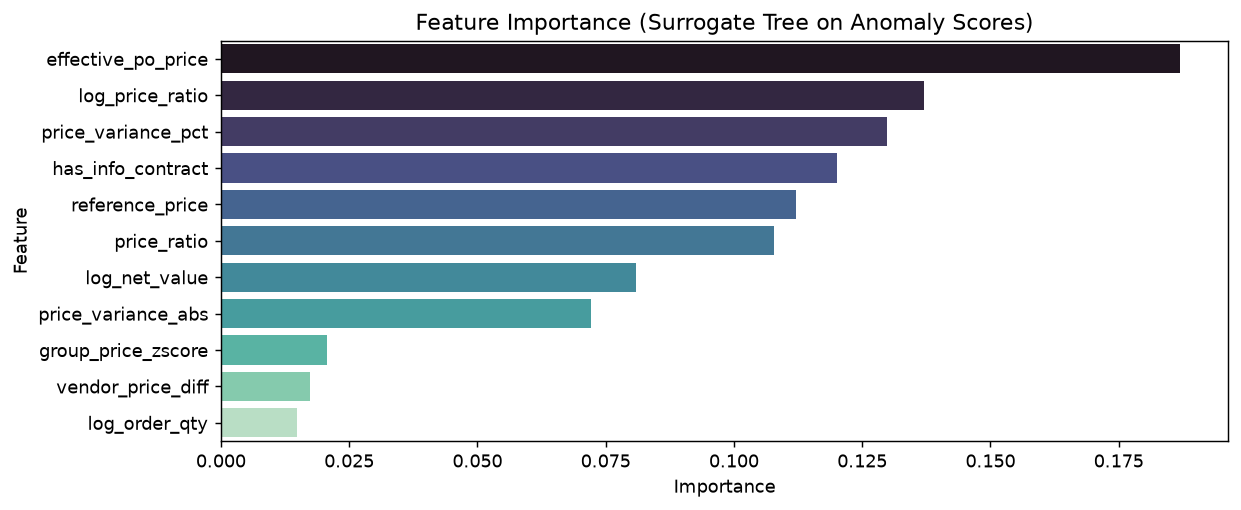

In [20]:
# 19. Feature Importance
surrogate = RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1)
surrogate.fit(X_test_scaled, scores_if)

feat_imp = pd.DataFrame({
    'Feature': FEATURE_COLS,
    'Importance': surrogate.feature_importances_
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 4))
sns.barplot(data=feat_imp, x='Importance', y='Feature', palette='mako')
plt.title('Feature Importance (Surrogate Tree on Anomaly Scores)')
plt.show()

feat_imp


In [21]:
# 20. Final Prediction
df_scored = df.loc[idx_test].copy()

for m, res in models_dict.items():
    df_scored[f"flag_{m.lower().replace(' ', '_')}"] = res['preds']

flag_cols = [f"flag_{m.lower().replace(' ', '_')}" for m in models_dict.keys()]
df_scored['consensus_count'] = df_scored[flag_cols].sum(axis=1)

champ_col = f"flag_{champion_model.lower().replace(' ', '_')}"
conditions = [
    (df_scored['consensus_count'] >= 3) | ((df_scored[champ_col] == 1) & (df_scored['price_variance_pct'] > 30.0)),
    (df_scored['consensus_count'] >= 2) | (df_scored[champ_col] == 1)
]
df_scored['risk_tier'] = np.select(conditions, ['High Risk', 'Medium Risk'], default='Low Risk')

print(df_scored['risk_tier'].value_counts())

audit_cols = ['po_number', 'po_item', 'material_id', 'material_desc', 'vendor_name', 'effective_po_price', 'reference_price', 'price_variance_pct', 'risk_tier', 'consensus_count']
df_scored[df_scored['risk_tier'] == 'High Risk'][audit_cols].sort_values(by='price_variance_pct', ascending=False).head(10)


risk_tier
Low Risk       3047
Medium Risk     727
High Risk       226
Name: count, dtype: int64


In [22]:
# 21. Save Model
os.makedirs("models", exist_ok=True)

bundle = {
    'champion_model': iso_forest if champion_model == 'Isolation Forest' else dbscan,
    'champion_name': champion_model,
    'scaler': scaler,
    'feature_cols': FEATURE_COLS
}

joblib.dump(bundle, "models/price_variance_model_bundle.joblib")
joblib.dump(scaler, "models/robust_scaler.joblib")
print("Saved models and scaler to models/")


Saved models and scaler to models/
